In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import kagglehub
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

filepath = ""
directory = kagglehub.dataset_download("aryashah2k/credit-card-customer-data")
import os
for dirname, _, filenames in os.walk(directory):
    for filename in filenames:
        filepath = os.path.join(dirname, filename)
print(filepath)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/Users/jcoelho/workspace/meia/jupyter-notebooks/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 6.28k/6.28k [00:00<00:00, 3.27MB/s]

Extracting files...
/Users/jcoelho/.cache/kagglehub/datasets/aryashah2k/credit-card-customer-data/versions/2/Credit Card Customer Data.csv


In [2]:
df = pd.read_csv(filepath)

### Clustering

In [6]:
from sklearn.cluster import (
    AffinityPropagation, MeanShift,
    SpectralClustering, AgglomerativeClustering,
    DBSCAN,OPTICS, Birch, KMeans
)
from sklearn.metrics import silhouette_score


In [13]:
models = {
    "kMeans": {"model": KMeans(n_clusters=3, n_init="auto", random_state=123)},
    "affinity": {"model": AffinityPropagation(damping=0.8)},
    "meanShift": {"model": MeanShift()},
    "spectral": {"model": SpectralClustering()},
    "agglomerative": {"model": AgglomerativeClustering()},
    "DBSCAN": {"model": DBSCAN()},
    "OPTICS": {"model": OPTICS()},
    "birch": {"model": Birch()}
}

for name, obj in models.items():
    try:
        model = obj['model']
        model.fit(df)
        clusters = model.labels_
        score = silhouette_score(df, clusters, metric="euclidean")
        obj['score'] = score
        print(f"{name}: {score}")
    except Exception as e:
        print(f"Model {name} failed: {e}")


kMeans: 0.39959041016269087
affinity: 0.4030263722073043
meanShift: 0.6358304173577437
spectral: -0.27614802265722765
agglomerative: 0.6377617406024266
Model DBSCAN failed: Number of labels is 1. Valid values are 2 to n_samples - 1 (inclusive)


/Users/jcoelho/workspace/meia/jupyter-notebooks/.venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


OPTICS: -0.08080150693200516
birch: 0.40647607954986437


### Visualize

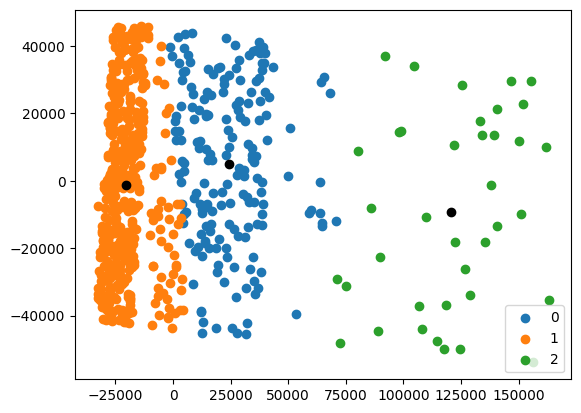

In [14]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

model = KMeans(n_clusters=3, n_init="auto", random_state=123)

model.fit(df)
clusters = model.labels_
centroids = model.cluster_centers_

df = PCA(n_components=2).fit_transform(df)

for element in np.unique(clusters):
    plt.scatter(df[clusters == element, 0], df[clusters == element, 1], label=element)

plt.scatter(centroids[:,0],centroids[:,1], color="k")
plt.legend()
plt.show()